# 音韵特征Ridge基准 / Phonological Ridge Baseline

本Notebook使用普通词训练音韵—感官评分映射，再在未见过的拟声拟态词上测试。它比较0、16、32个拟声拟态词支持样本，并同时计算平均值基准。

This notebook learns a phonology-to-sensory-rating mapping from ordinary Japanese words and evaluates it on held-out ideophones. It compares 0, 16, and 32 labeled ideophone support items.

**注意：** 三折使用自动生成的词族候选，正式论文分析前需要人工确认。


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROJECT_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "japanese_sensory_modeling.csv"
COLAB_DATA_PATH = Path("/content/japanese_sensory_modeling.csv")
DATA_PATH = PROJECT_DATA_PATH if PROJECT_DATA_PATH.exists() else COLAB_DATA_PATH

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Data file not found. In Colab, upload japanese_sensory_modeling.csv "
        "to the session storage (/content), then run this cell again."
    )

print(f"Using data file: {DATA_PATH}")
DATA_PATH


Using data file: /Users/Nathan/Documents/ChatGPT/日语拟声词/data/processed/japanese_sensory_modeling.csv


PosixPath('/Users/Nathan/Documents/ChatGPT/日语拟声词/data/processed/japanese_sensory_modeling.csv')

## 1. 读取并检查数据 / Load and validate the data

主文件保留510个词。正式分析只筛选 `use_in_primary_analysis == 1`，因此不会物理删除6个待核对词。


In [2]:
data = pd.read_csv(DATA_PATH)

required_counts = {
    "all_words": len(data),
    "primary_words": int(data["use_in_primary_analysis"].sum()),
    "ordinary_primary": int(((data["use_in_primary_analysis"] == 1) & (data["is_ideophone"] == 0)).sum()),
    "ideophone_primary": int(((data["use_in_primary_analysis"] == 1) & (data["is_ideophone"] == 1)).sum()),
    "excluded_pending": int((data["use_in_primary_analysis"] == 0).sum()),
}
required_counts


{'all_words': 510,
 'primary_words': 504,
 'ordinary_primary': 396,
 'ideophone_primary': 108,
 'excluded_pending': 6}

In [3]:
assert required_counts == {
    "all_words": 510,
    "primary_words": 504,
    "ordinary_primary": 396,
    "ideophone_primary": 108,
    "excluded_pending": 6,
}

data.loc[data["use_in_primary_analysis"] == 0,
         ["word_id", "word_japanese", "romanized", "is_ideophone",
          "rating_issue_codes", "primary_exclusion_reason"]]


,word_id,word_japanese,romanized,is_ideophone,rating_issue_codes,primary_exclusion_reason
5,jpn_0006,ばちゃばちゃ,bachabacha,1,duplicate_participant_rating,duplicate_participant_rating
102,jpn_0103,わくわく,wakuwaku,1,partial_ratings_under_canonical_key,partial_ratings_under_canonical_key
109,jpn_0110,びくっ,bikuQ,1,conflicting_rated_forms,conflicting_rated_forms
153,jpn_0154,取り組む,torikumu,0,conflicting_rated_forms,conflicting_rated_forms
266,jpn_0267,わさわさ,wasawasa,1,partial_ratings_under_canonical_key,partial_ratings_under_canonical_key
456,jpn_0457,着る,kiru_put.on,0,partial_ratings_under_canonical_key,partial_ratings_under_canonical_key


## 2. 定义输入和预测目标 / Define features and targets

模型A只使用12个音韵特征。六项感官平均评分是预测目标。


In [4]:
FEATURE_COLUMNS = [
    "feature_mora_count",
    "feature_full_reduplication",
    "feature_sokuon_count",
    "feature_moraic_n_count",
    "feature_long_mark_count",
    "feature_voiced_obstruent_mora_count",
    "feature_p_series_mora_count",
    "feature_vowel_a_mora_count",
    "feature_vowel_i_mora_count",
    "feature_vowel_u_mora_count",
    "feature_vowel_e_mora_count",
    "feature_vowel_o_mora_count",
]

LABEL_COLUMNS = [
    "visual_mean",
    "auditory_mean",
    "haptic_mean",
    "olfactory_mean",
    "gustatory_mean",
    "interoceptive_mean",
]

primary = data.loc[data["use_in_primary_analysis"] == 1].copy()
assert primary[FEATURE_COLUMNS + LABEL_COLUMNS].notna().all().all()
assert set(primary.loc[primary["is_ideophone"] == 1, "outer_fold_provisional"].astype(int)) == {1, 2, 3}

primary.groupby(["analysis_role", "outer_fold_provisional"], dropna=False).size()


analysis_role     outer_fold_provisional
ideophone_target  1.0                        36
                  2.0                        36
                  3.0                        36
ordinary_source   NaN                       396
dtype: int64

## 3. 建立训练集和测试集 / Build train and test sets

- 所有396个普通词始终进入训练集。
- 当前外层折中的拟声拟态词只用于测试。
- 16和32个支持词从另外两折抽取。
- 同一随机种子下，16个词是32个词的子集。


In [5]:
SUPPORT_SIZES = [0, 16, 32]
SUPPORT_SEEDS = [13, 29, 47, 71, 101]
ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0]


def make_split(frame, test_fold, support_size, seed):
    ordinary = frame.loc[frame["is_ideophone"] == 0].copy()
    ideophones = frame.loc[frame["is_ideophone"] == 1].copy()

    test = ideophones.loc[ideophones["outer_fold_provisional"] == test_fold].copy()
    support_pool = ideophones.loc[ideophones["outer_fold_provisional"] != test_fold].copy()
    shuffled = support_pool.sample(frac=1, random_state=seed)
    support = shuffled.head(support_size).copy()
    train = pd.concat([ordinary, support], ignore_index=True)

    assert set(train["word_id"]).isdisjoint(set(test["word_id"]))
    train_target_families = set(support["family_candidate_key"])
    test_families = set(test["family_candidate_key"])
    assert train_target_families.isdisjoint(test_families)
    return train, test, support


example_train, example_test, example_support = make_split(primary, 1, 16, 13)
{
    "train_rows": len(example_train),
    "test_rows": len(example_test),
    "support_rows": len(example_support),
}


{'train_rows': 412, 'test_rows': 36, 'support_rows': 16}

## 4. 训练平均值基准和Ridge / Train the mean and Ridge baselines

标准化和Ridge正则强度选择都只在训练数据内部完成。外层测试折不会参与模型选择。


In [6]:
def average_dimension_spearman(y_true, y_pred):
    values = []
    for column_index in range(y_true.shape[1]):
        correlation = spearmanr(y_true[:, column_index], y_pred[:, column_index]).statistic
        if np.isfinite(correlation):
            values.append(float(correlation))
    return float(np.mean(values)) if values else np.nan


def evaluate_predictions(y_true, y_pred):
    metrics = {
        "mae_overall": mean_absolute_error(y_true, y_pred),
        "spearman_mean": average_dimension_spearman(y_true, y_pred),
    }
    for index, label in enumerate(LABEL_COLUMNS):
        metrics[f"mae_{label.removesuffix('_mean')}"] = mean_absolute_error(
            y_true[:, index], y_pred[:, index]
        )
    return metrics


def fit_ridge(train, test):
    train_groups = train["family_candidate_key"].fillna(train["word_id"])
    inner_cv = GroupKFold(n_splits=3)
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge()),
    ])
    search = GridSearchCV(
        pipeline,
        param_grid={"ridge__alpha": ALPHAS},
        scoring="neg_mean_absolute_error",
        cv=inner_cv,
        n_jobs=-1,
    )
    search.fit(train[FEATURE_COLUMNS], train[LABEL_COLUMNS], groups=train_groups)
    predictions = search.predict(test[FEATURE_COLUMNS])
    return predictions, float(search.best_params_["ridge__alpha"])


In [7]:
run_rows = []
prediction_rows = []

for support_size in SUPPORT_SIZES:
    seeds = [SUPPORT_SEEDS[0]] if support_size == 0 else SUPPORT_SEEDS
    for seed in seeds:
        for test_fold in [1, 2, 3]:
            train, test, support = make_split(primary, test_fold, support_size, seed)
            y_true = test[LABEL_COLUMNS].to_numpy()

            mean_prediction = np.tile(
                train[LABEL_COLUMNS].mean().to_numpy(),
                (len(test), 1),
            )
            ridge_prediction, best_alpha = fit_ridge(train, test)

            for model_name, prediction, alpha in [
                ("mean_baseline", mean_prediction, np.nan),
                ("ridge_phonology", ridge_prediction, best_alpha),
            ]:
                metrics = evaluate_predictions(y_true, prediction)
                run_rows.append({
                    "model": model_name,
                    "support_size": support_size,
                    "seed": seed,
                    "test_fold": test_fold,
                    "n_train": len(train),
                    "n_test": len(test),
                    "best_alpha": alpha,
                    **metrics,
                })

                for row_position, (_, test_row) in enumerate(test.iterrows()):
                    record = {
                        "model": model_name,
                        "support_size": support_size,
                        "seed": seed,
                        "test_fold": test_fold,
                        "word_id": test_row["word_id"],
                        "word_japanese": test_row["word_japanese"],
                    }
                    for label_index, label in enumerate(LABEL_COLUMNS):
                        short = label.removesuffix("_mean")
                        record[f"true_{short}"] = y_true[row_position, label_index]
                        record[f"pred_{short}"] = prediction[row_position, label_index]
                    prediction_rows.append(record)

run_metrics = pd.DataFrame(run_rows)
predictions = pd.DataFrame(prediction_rows)

run_metrics.to_csv(RESULTS_DIR / "ridge_run_metrics.csv", index=False)
predictions.to_csv(RESULTS_DIR / "ridge_predictions.csv", index=False)

run_metrics.head()


,model,support_size,seed,test_fold,n_train,n_test,best_alpha,mae_overall,spearman_mean,mae_visual,mae_auditory,mae_haptic,mae_olfactory,mae_gustatory,mae_interoceptive
0,mean_baseline,0,13,1,396,36,NaN,0.772132,NaN,0.707812,0.893961,0.925695,0.544471,0.837437,0.723418
1,ridge_phonology,0,13,1,396,36,100.0,0.814245,0.022637,0.710866,0.853388,1.048091,0.638618,0.862341,0.772168
2,mean_baseline,0,13,2,396,36,NaN,0.727535,NaN,0.713576,0.808562,0.955392,0.535695,0.643693,0.708289
3,ridge_phonology,0,13,2,396,36,100.0,0.718764,0.170701,0.706394,0.800618,0.964754,0.527379,0.622428,0.691011
4,mean_baseline,0,13,3,396,36,NaN,0.731918,NaN,0.629531,0.850817,1.109378,0.629972,0.599945,0.571865


## 5. 汇总结果 / Summarize the results

下面的表格给出每种条件的平均MAE。MAE越低，预测越准确。


In [8]:
summary = (
    run_metrics
    .groupby(["model", "support_size"], as_index=False)
    .agg(
        mae_mean=("mae_overall", "mean"),
        mae_sd=("mae_overall", "std"),
        spearman_mean=("spearman_mean", "mean"),
        runs=("mae_overall", "size"),
    )
)
summary["mae_sd"] = summary["mae_sd"].fillna(0)
summary


,model,support_size,mae_mean,mae_sd,spearman_mean,runs
0,mean_baseline,0,0.743862,0.024581,NaN,3
1,mean_baseline,16,0.742456,0.020860,NaN,15
2,mean_baseline,32,0.741383,0.020871,NaN,15
3,ridge_phonology,0,0.768510,0.047867,0.085915,3
4,ridge_phonology,16,0.781244,0.032026,0.036509,15
5,ridge_phonology,32,0.753944,0.033125,0.071177,15


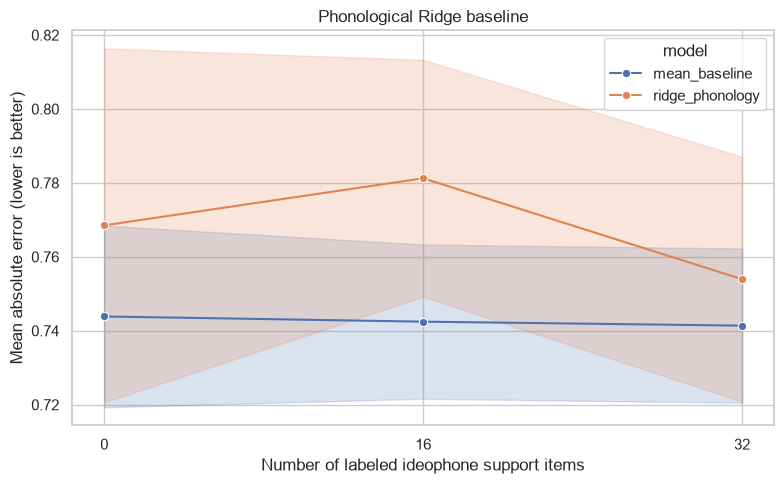

In [9]:
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=run_metrics,
    x="support_size",
    y="mae_overall",
    hue="model",
    marker="o",
    errorbar="sd",
)
plt.xlabel("Number of labeled ideophone support items")
plt.ylabel("Mean absolute error (lower is better)")
plt.title("Phonological Ridge baseline")
plt.xticks(SUPPORT_SIZES)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ridge_learning_curve.png", dpi=200)
plt.show()


## 6. 如何解释 / Interpretation checklist

1. Ridge是否优于平均值基准？如果没有，音韵特征目前没有显示稳定预测能力。
2. 16样本是否优于0样本？这反映少量拟声拟态词能否帮助模型适应目标类别。
3. 32样本是否继续改善？如果没有，可能需要检查支持词选择、词族划分或模型形式。
4. 哪个感官维度的MAE下降最多？这可以形成后续语言学分析。

这一阶段不能单独证明音韵具有额外价值。完整论文还需要将模型A与仅文本模型B、文本加音韵模型C进行比较。
